# Ejercicio 2 — YOLO11n: confianza y NMS

Detección sin entrenamiento. Imagen: `data/crowd.jpg` (Shutterstock, recurso 86973980; licencia por verificar). Pesos oficiales: [yolo11n.pt](https://github.com/ultralytics/assets/releases/download/v8.3.0/yolo11n.pt). Los archivos se leen localmente.

Ejecuta con el entorno indicado en el README principal, desde la raíz o la carpeta del ejercicio.

In [1]:
from pathlib import Path
import os
import sys

cwd = Path.cwd().resolve()
ROOT = cwd if (cwd / 'yolo.ipynb').exists() else (cwd / '02_yolo' if (cwd / '02_yolo' / 'yolo.ipynb').exists() else cwd / 'ejercicios' / '02_yolo')
assert (ROOT / 'yolo.ipynb').is_file(), f'No se encuentra el ejercicio desde {cwd}'
for folder in ('data', 'models', 'outputs'):
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
os.environ['YOLO_CONFIG_DIR'] = str(ROOT / 'outputs' / 'ultralytics_config')
os.environ['MPLCONFIGDIR'] = str(ROOT / 'outputs' / 'matplotlib_config')
import torch
import ultralytics
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2

device = 0 if torch.cuda.is_available() else 'cpu'
print(f'Python: {sys.executable} | Ultralytics: {ultralytics.__version__} | Torch: {torch.__version__} | dispositivo: {device}')

Python: C:\Users\steve\Desktop\Examen_EU4_CV\ejercicios\02_yolo\.venv\Scripts\python.exe | Ultralytics: 8.4.202 | Torch: 2.15.0+cpu | dispositivo: cpu


## Imagen y pesos locales

Modelo disponible: C:\Users\steve\Desktop\Examen_EU4_CV\ejercicios\02_yolo\models\yolo11n.pt | bytes: 5613764


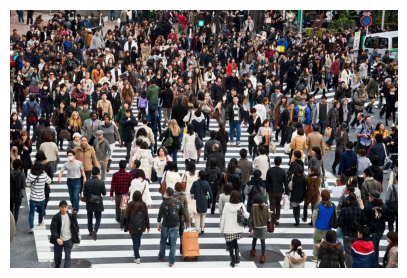

In [2]:
image = ROOT / 'data' / 'crowd.jpg'
weights = ROOT / 'models' / 'yolo11n.pt'
for path in (image, weights):
    if not path.is_file() or path.stat().st_size == 0:
        raise FileNotFoundError(f'Archivo local ausente o vacío: {path}')
print('Modelo disponible:', weights, '| bytes:', weights.stat().st_size)
img = cv2.imread(str(image))
assert img is not None, f'No se pudo leer {image}'
plt.figure(figsize=(5, 6)); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()
model = YOLO(str(weights))

## Baseline y barrido de parámetros

Mantenemos la imagen, el tamaño de entrada y el dispositivo constantes. El baseline es `conf=0.25, iou=0.50`. No hay etiquetas de referencia: el número de detecciones **no** mide precisión ni recall.

In [3]:
# conf: umbral mínimo de confianza para conservar una detección.
# iou: umbral de solapamiento entre cajas utilizado por NMS para suprimir
# cajas redundantes de la misma clase; no es IoU contra ground truth.
def infer(conf, iou):
    return model.predict(source=str(image), conf=conf, iou=iou, imgsz=640,
                         device=device, verbose=False, save=False)[0]

baseline = infer(0.25, 0.50)
print('Baseline: conf=0.25, iou=0.50; detecciones:', len(baseline.boxes))
results = {(0.25, 0.50): baseline}
for conf, iou in [(0.10, 0.50), (0.50, 0.50), (0.25, 0.30), (0.25, 0.70)]:
    results[(conf, iou)] = infer(conf, iou)
for (conf, iou), result in results.items():
    print(f'conf={conf:.2f} iou={iou:.2f}: {len(result.boxes)} detecciones')

Baseline: conf=0.25, iou=0.50; detecciones: 16


conf=0.25 iou=0.50: 16 detecciones
conf=0.10 iou=0.50: 37 detecciones
conf=0.50 iou=0.50: 7 detecciones
conf=0.25 iou=0.30: 16 detecciones
conf=0.25 iou=0.70: 16 detecciones


## Comparaciones visuales

Con `conf` mayor se descartan candidatos de menor confianza. Un IoU de NMS mayor suele permitir más cajas solapadas, pero puede no cambiar nada en una imagen concreta.

{'conf': 0.1, 'iou_nms': 0.5, 'detecciones': 37, 'clases': "{'person': 30, 'suitcase': 1, 'backpack': 2, 'truck': 1, 'handbag': 3}", 'conf_min': 0.1023988127708435, 'conf_max': 0.7215262651443481}
{'conf': 0.25, 'iou_nms': 0.3, 'detecciones': 16, 'clases': "{'person': 14, 'suitcase': 1, 'backpack': 1}", 'conf_min': 0.2736301124095917, 'conf_max': 0.7215262651443481}
{'conf': 0.25, 'iou_nms': 0.5, 'detecciones': 16, 'clases': "{'person': 14, 'suitcase': 1, 'backpack': 1}", 'conf_min': 0.2736301124095917, 'conf_max': 0.7215262651443481}
{'conf': 0.25, 'iou_nms': 0.7, 'detecciones': 16, 'clases': "{'person': 14, 'suitcase': 1, 'backpack': 1}", 'conf_min': 0.2736301124095917, 'conf_max': 0.7215262651443481}
{'conf': 0.5, 'iou_nms': 0.5, 'detecciones': 7, 'clases': "{'person': 6, 'suitcase': 1}", 'conf_min': 0.5382600426673889, 'conf_max': 0.7215262651443481}


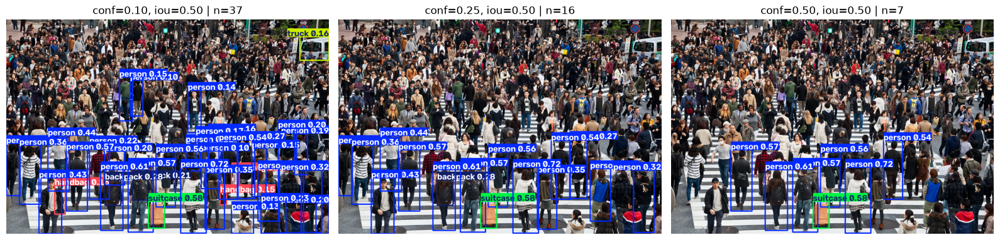

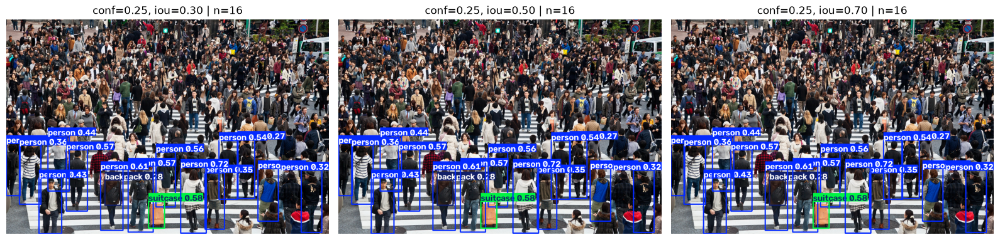

In [4]:
import csv
from collections import Counter
rows = []
for (c, i), r in sorted(results.items()):
    clases = Counter(r.names[int(cls)] for cls in r.boxes.cls.cpu().tolist())
    scores = r.boxes.conf.cpu().tolist()
    rows.append({'conf': c, 'iou_nms': i, 'detecciones': len(r.boxes),
                 'clases': str(dict(clases)), 'conf_min': min(scores, default=None),
                 'conf_max': max(scores, default=None)})
with (ROOT / 'outputs' / 'detecciones.csv').open('w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=['conf', 'iou_nms', 'detecciones', 'clases', 'conf_min', 'conf_max'])
    writer.writeheader(); writer.writerows(rows)
for row in rows:
    print(row)

def comparar(configs, filename):
    fig, axes = plt.subplots(1, 3, figsize=(16, 8))
    for ax, (c, i) in zip(axes, configs):
        r = results[(c, i)]
        # result.plot devuelve BGR; Matplotlib necesita RGB.
        ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
        ax.set_title(f'conf={c:.2f}, iou={i:.2f} | n={len(r.boxes)}')
        ax.axis('off')
    fig.tight_layout()
    fig.savefig(ROOT / 'outputs' / filename, dpi=140, bbox_inches='tight')
    plt.show()

comparar([(0.10, 0.50), (0.25, 0.50), (0.50, 0.50)], 'comparacion_conf.png')
comparar([(0.25, 0.30), (0.25, 0.50), (0.25, 0.70)], 'comparacion_iou.png')

In [5]:
# Compara también cajas, clases y confianzas, no solo el número de cajas.
def firma(r):
    return sorted(tuple(round(float(v), 4) for v in row) for row in r.boxes.data.cpu().tolist())
same = firma(results[(0.25, 0.30)]) == firma(results[(0.25, 0.50)]) == firma(results[(0.25, 0.70)])
print('Resultados idénticos para los tres valores de IoU:', same)
if same:
    print('En esta imagen, el cambio de IoU no alteró las cajas finales; ninguna diferencia de supresión afectó al resultado final en ese intervalo.')
else:
    print('Al variar IoU cambió al menos una caja, clase o confianza; revisar la comparación visual.')
for (c, i), r in sorted(results.items()):
    base = results[(0.25, 0.50)]
    actual, ref = set(firma(r)), set(firma(base))
    print(f'conf={c:.2f}, iou={i:.2f}: {len(actual-ref)} cajas nuevas y {len(ref-actual)} ausentes frente al baseline (comparación exacta redondeada a 4 decimales)')
print('Conteos guardados en', ROOT / 'outputs' / 'detecciones.csv')

Resultados idénticos para los tres valores de IoU: True
En esta imagen, el cambio de IoU no alteró las cajas finales; ninguna diferencia de supresión afectó al resultado final en ese intervalo.
conf=0.10, iou=0.50: 21 cajas nuevas y 0 ausentes frente al baseline (comparación exacta redondeada a 4 decimales)
conf=0.25, iou=0.30: 0 cajas nuevas y 0 ausentes frente al baseline (comparación exacta redondeada a 4 decimales)
conf=0.25, iou=0.50: 0 cajas nuevas y 0 ausentes frente al baseline (comparación exacta redondeada a 4 decimales)
conf=0.25, iou=0.70: 0 cajas nuevas y 0 ausentes frente al baseline (comparación exacta redondeada a 4 decimales)
conf=0.50, iou=0.50: 0 cajas nuevas y 9 ausentes frente al baseline (comparación exacta redondeada a 4 decimales)
Conteos guardados en C:\Users\steve\Desktop\Examen_EU4_CV\ejercicios\02_yolo\outputs\detecciones.csv


## Conclusión

La comparación es descriptiva para una sola imagen. El IoU de NMS controla supresión de predicciones redundantes y no debe confundirse con IoU de evaluación frente a anotaciones. Sin ground truth no se puede afirmar que una configuración sea más precisa.

## Análisis complementario: recuperación de objetos pequeños en escenas concurridas

**Diagnóstico.** El baseline obligatorio usa `imgsz=640`: 1880×1254 pasa a aproximadamente 640×427 antes del padding al múltiplo del stride. Las formas observadas del tensor se registran mediante un hook. `max_det=300` no limita las 16 detecciones (14 personas). `Results.plot()` dibuja en coordenadas originales; se convierte BGR→RGB al mostrar. Oclusión, reducción de detalle y capacidad de YOLO11n son causas plausibles de omisiones; NMS no es la única causa.

**Referencia:** la búsqueda pública por `shutterstock 86973980 crowd people count` encontró la fotografía en [una publicación de salud](https://management-krankenhaus.de/de/news/die-gesundheit-der-bevoelkerung-im-europaeischen-vergleich), pero no un conteo verificable. No hay ground truth disponible para este análisis. No damos un conteo manual sin marcar exhaustivamente personas: cabezas parcialmente ocultas y recortes de borde hacen ambigua esa estimación. No se reportan precision, recall, F1 ni mAP.

**Protocolo:** solo personas (`classes=[0]`), YOLO11n local, sin entrenamiento. Resoluciones a conf=0.25; después barrido de confianza en 1280 para conservar detalle. Tiempos: mediana de tres ejecuciones tras calentamiento, extremo a extremo sin dibujo. Slicing: tiles 640, paso 512, coordenadas trasladadas, NMS global 0.50 independiente del IoU local de YOLO. Los pares con IoU>0.70 son candidatos a duplicación, NO falsos positivos certificados.

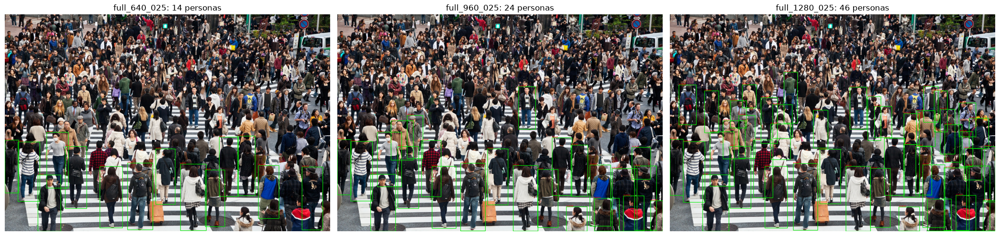

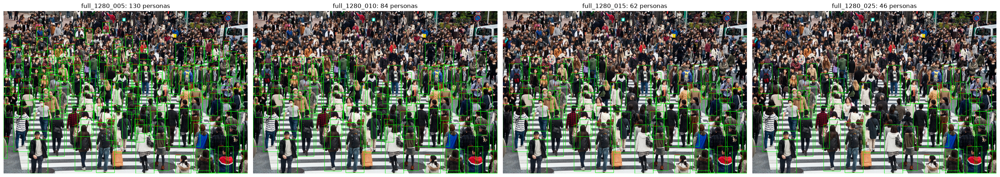

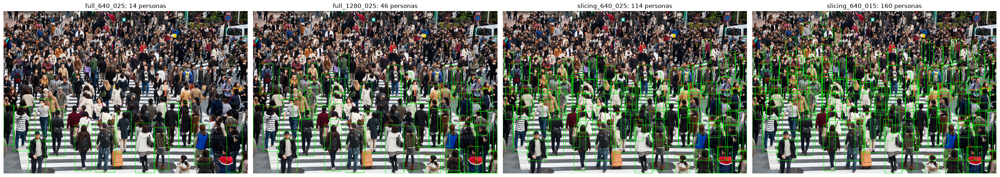

| Método | imgsz | conf | Personas | Conf. mín/media/máx | Tiempo (ms) |
|---|---:|---:|---:|---|---:|
| full_640_025 | 640 | 0.25 | 14 | 0.274/0.455/0.722 | 58.1 |
| full_960_025 | 960 | 0.25 | 24 | 0.252/0.532/0.785 | 94.7 |
| full_1280_025 | 1280 | 0.25 | 46 | 0.269/0.496/0.828 | 238.1 |
| full_1280_005 | 1280 | 0.05 | 130 | 0.051/0.244/0.828 | 180.6 |
| full_1280_010 | 1280 | 0.10 | 84 | 0.101/0.340/0.828 | 161.4 |
| full_1280_015 | 1280 | 0.15 | 62 | 0.152/0.417/0.828 | 171.2 |
| slicing_640_025 | 640 | 0.25 | 114 | 0.256/0.585/0.908 | 800.9 |
| slicing_640_015 | 640 | 0.15 | 160 | 0.151/0.472/0.908 | 746.7 |

{
  "tensor_shapes": [
    [
      1,
      3,
      448,
      640
    ],
    [
      1,
      3,
      640,
      640
    ],
    [
      1,
      3,
      640,
      960
    ],
    [
      1,
      3,
      864,
      1280
    ]
  ],
  "original_hw": [
    1254,
    1880
  ],
  "max_det": 300,
  "iou_local": 0.5,
  "iou_global_slicing": 0.5,
  "tiles": 12,
  "tiempo": "mediana de 3 repeticiones tras calentamiento, extremo a extremo; sin dibujo",
  "device": "cpu",
  "rect": true,
  "stride": 32,
  "letterbox_full": [
    {
      "imgsz": 640,
      "scale": 0.3404255319148936,
      "resize_wh": [
        640,
        427
      ],
      "tensor_hw": [
        448,
        640
      ]
    },
    {
      "imgsz": 960,
      "scale": 0.5106382978723404,
      "resize_wh": [
        960,
        640
      ],
      "tensor_hw": [
        640,
        960
      ]
    },
    {
      "imgsz": 1280,
      "scale": 0.6808510638297872,
      "resize_wh": [
        1280,
        854
      ],
   

In [6]:
import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from complementario import ejecutar
registros_extra, cajas_extra = ejecutar(model, img, ROOT, device)
from IPython.display import display, Markdown
tabla = ['| Método | imgsz | conf | Personas | Conf. mín/media/máx | Tiempo (ms) |',
         '|---|---:|---:|---:|---|---:|']
for f in registros_extra:
    tabla.append(f"| {f['metodo']} | {f['imgsz']} | {f['conf']:.2f} | {f['personas']} | {f['conf_min']:.3f}/{f['conf_media']:.3f}/{f['conf_max']:.3f} | {f['tiempo_ms']:.1f} |")
display(Markdown(chr(10).join(tabla)))
print((ROOT / 'outputs' / 'diagnostico.json').read_text())

### Interpretación

Las figuras comparan detecciones de **personas**, no todas las clases. Aumentar resolución evita perder tantos píxeles por persona; slicing presenta cada región a mayor escala efectiva, pero corta cuerpos en sus bordes y puede generar duplicados con cajas distintas que sobreviven al NMS global. Reducir confianza admite tanto personas reales como respuestas inciertas. Solapamiento entre personas distintas no implica duplicación. Sin anotaciones, más cajas no demuestra mejor precisión.

**Inspección visual organizada:** primer plano (y≥800), zona media (400≤y<800) y fondo (y<400). Los IDs y scores en los JPG individuales permiten revisar cajas. En slicing se aprecian cajas de cuerpo parciales que terminan en límites de tile, por ejemplo alrededor de la persona con jersey claro en x≈160, y≈650. En conf=0.05 aparecen cajas de cabeza/cuerpo de una misma persona y candidatos ambiguos. No se identificó ni anotó exhaustivamente cada falso positivo: no hay una cantidad verificada. Cero pares con IoU>0.70 no descarta duplicados de distinto tamaño. La columna de centros en el fondo describe localización de cajas, no cuenta personas reales.

**Recomendación provisional:** imagen completa, `imgsz=1280, conf=0.15, iou=0.50, classes=[0]`: 62 cajas de persona frente a las 14 del baseline. Al revisar las 16 cajas adicionales respecto a conf=0.25 se observan candidatos sobre personas visibles de la zona media, aunque siguen siendo predicciones, no aciertos certificados. Es un compromiso conservador por simplicidad y ausencia de fragmentación artificial por tiles. Slicing a conf=0.25 ofrece mayor cobertura exploratoria (114 cajas), pero exige revisión de duplicados; no es un conteo de personas distintas. Conf=0.05 (130 cajas) no se recomienda como resultado principal solo por producir más detecciones. La multitud lejana sigue muy incompleta.

**Limitaciones del experimento:** una imagen, sin anotaciones, CPU y tres repeticiones; los tiempos tienen variabilidad y no permiten atribuir pequeñas diferencias al umbral. No había YOLO11s local y no se descargaron pesos adicionales. El experimento obligatorio se conserva intacto; este complemento no sustituye sus comparaciones de conf/NMS.